In [3]:
# Kristen Aalbue
# Lab 7
import numpy as np
import matplotlib.pyplot as plt
import os

In [21]:
# pendulum eq from Lab 5
    # initial conditions:
l = 10
g = 9.8
m = 1
omega = np.sqrt(g/l)
theta0 = np.pi/6
v0 = 0

    # pendulum eq:
def pend(t,theta,v):
    return -(g/l)*np.sin(theta)
    
    # from previous labs:
def euler_newton(force, times, x0, v0, m,dt):
    # create arrays for x and v
    x = []
    v = []
    # store the initial conditions in the first elements
    x.append(x0)
    v.append(v0)
    
    for i in range(nsteps-1):
        a = force(times[i], x[i], v[i]) / m
        v.append(v[i] + (a * dt))
        x.append(x[i] + (v[i] * dt))
    return x, v
nsteps=1000000
times,dt = np.linspace(0, 10, nsteps, retstep=True)

theta,v = euler_newton(pend, times, theta0, v0, m, dt)

# small angle approx.
theta_saa = theta0*np.cos(omega*times)

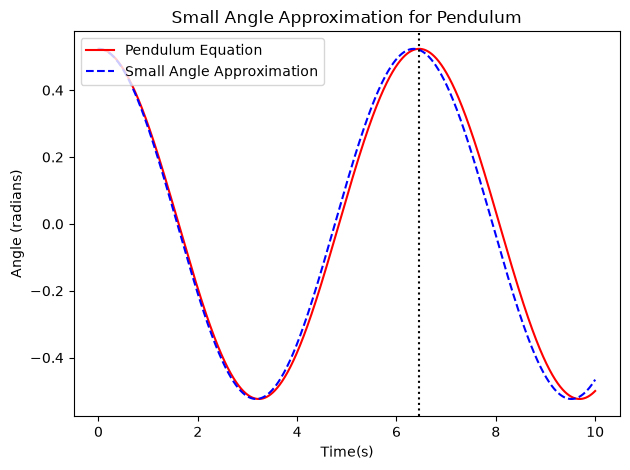

In [22]:
plt.plot(times,theta,label='Pendulum Equation',c='r')
plt.plot(times,theta_saa,label='Small Angle Approximation',c='b',ls='--')

plt.xlabel("Time(s)")
plt.ylabel("Angle (radians)")
plt.title("Small Angle Approximation for Pendulum")
plt.axvline(x=6.45,ls=':',c='black')
plt.grid
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [31]:
sim = 6.45
 #approx. from above simulation
analy = 2*np.pi/omega
 #from lab 5: omega=sqrt(g/l), T=(2pi/omega), SAA/analytical result=2pi*sqrt(10/9.8)= ~6.35s
print(sim)
print(analy)

6.45
6.346975625940523


In [32]:
# figure of merit: percent difference between our simulated and analytical pendulum eqs

difference = abs(sim - analy)/analy*100
print("Percent Difference(%)", difference)

Percent Difference(%) 1.6232041862333537


Q1. For my figure of merit, I chose to use the percent difference between our simulated and analytical values. |Tsim-Tanalytical|/Tanalytical*(100). I found the analytical period in Lab 5 by using the formula T=2pi/omega where omega=sqrt(g/l). This resulted in a period of approx. 6.35s for a 30 degree angle. The simulation shows a full period lasts about 6.4-6.45s.

Q2. As the initial angle increases, the simulation and analytical results skew further from one another. Since the small angle approximation takes sin(theta)=theta, as the angle increases, that approx. becomes much less accurate.

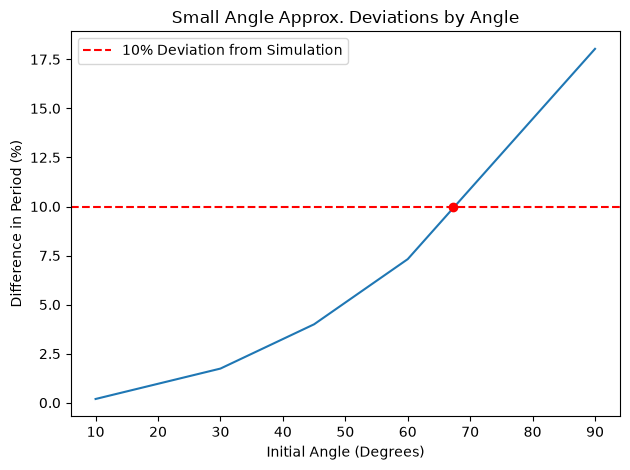

In [47]:
# FOM across multiple angles:
angles = [10,30,45,60,90]
differences = []
analy = 2*np.pi/omega

for angle in angles:
    theta0=np.radians(angle)

    theta,v = euler_newton(pend,times,theta0,v0,m,dt)
    for i in range(1,nsteps):
        if v[i-1]>0 and v[i]<=0:
            sim=times[i]
            break
        #double check that i implemented this correctly!
    difference = abs(sim - analy)/analy*100
    differences.append(difference)


plt.plot(angles,differences)
plt.xlabel("Initial Angle (Degrees)")
plt.ylabel("Difference in Period (%)")
plt.title("Small Angle Approx. Deviations by Angle")
plt.axhline(y=10, label='10% Deviation from Simulation', ls='--', c='r')
plt.plot(67.3,10,'ro')
plt.grid
plt.legend()
plt.tight_layout()
plt.show()

Q3. The 10% deviation from the analytical solutions seems to appear at around an angle of 67 degrees.

Q4. An increase in the mass would not affect the pendulum's motion. Mass will cancel out of the equations of motion via N2L. Even though a larger mass results in a greater gravitational force, it also results in greater inertia. Therefore, the mass and velocity balamce each other out essentially.